In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Setup and imports for archetypal analysis using the new package
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import matplotlib.pyplot as plt
import os
import json
import sys

# Import the new archetypal_analysis package
sys.path.append('./archetypal_analysis')

from archetypal_analysis.data.loaders import CompendiumDataLoader, HadzaDataLoader, ArchetypalResultLoader
from archetypal_analysis.data.normalizers import DataNormalizer
from archetypal_analysis.data.formatters import DataTransformer
from archetypal_analysis.data.quality_control import QualityController
from archetypal_analysis.analysis.archetypal import ArchetypalAnalysis, ArchetypalAnalysisResult
from archetypal_analysis.analysis.metrics import AnalysisMetrics
from archetypal_analysis.visualization.simplex import SimplexPlotter, plot_multiple_k_simplex
from archetypal_analysis.visualization.pcoa import PCoAVisualizer
from archetypal_analysis.visualization.composition import CompositionAnalyzer

from archetypal_analysis.visualization.stacked_bar import StackedBarPlotter, plot_archetype_composition_bars, plot_stacked_bar_composition
from archetypal_analysis.utils.metadata import extract_metadata_compendium
from archetypal_analysis.utils.file_io import ResultsManager
from archetypal_analysis.config import AnalysisConfig

# For compatibility with original archetypes package visualization
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset

print("Archetypal analysis package loaded successfully!")

Couldn't import dot_parser, loading of dot files will not be possible.
Archetypal analysis package loaded successfully!


## Performing AA

In [3]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = r"datasets\compendium\normalized\compendium_Norm_QC-sample_type400.csv"

loader = CompendiumDataLoader()
otu = loader.load_otu_table(otuFile)

In [9]:
FRAC = 1.0
LOG_TRANSFORM = True
N_ARCHETYPES = 5
aa = ArchetypalAnalysis(
    n_archetypes=N_ARCHETYPES,
    method="pgd",
    max_iter=100,
)

result = aa.fit_transform(otu, 
                          apply_log_transform=LOG_TRANSFORM, 
                          sample_fraction=FRAC)


Starting archetypal analysis with 5 archetypes...
Input data shape: (333, 574)
Processed data shape: (333, 574)
Fitting archetypal analysis model...
Model fitting completed.
Analysis completed. Final loss: 508658.840836


In [10]:
aa.save_results(result, outDir, frac=FRAC)

Saved archetypal analysis results to results\otu_AA_K5_1.0_None_jensenshannon.json


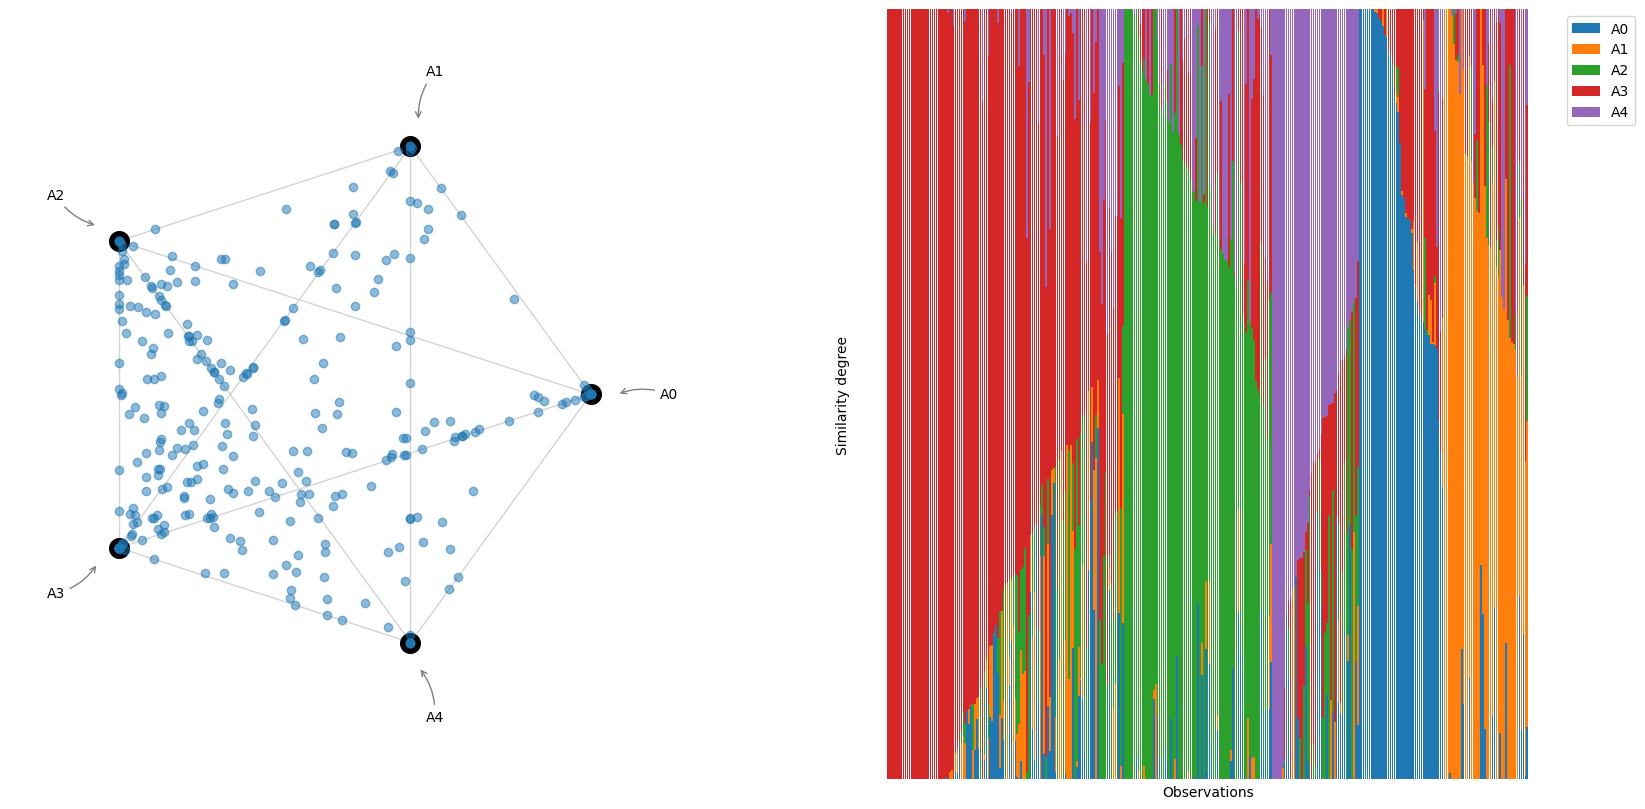

In [12]:
otu_np = otu.to_numpy()

# Get similarity degree and archetypes from the result object
similarity_degree = result.similarity_degree.to_numpy()
archetypes = result.archetypes

data_sorted, info = sort_by_archetype_similarity(otu_np, [similarity_degree], archetypes)
similarity_degree_permuted, _ = permute_dataset(similarity_degree, info["perms"])

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
simplex(similarity_degree, alpha=0.5, ax=ax[0], show_vertices=True)
stacked_bar(similarity_degree_permuted, ax=ax[1])

plt.show()


## Standard Analysis

### Loading Results

In [60]:
dataDir = "datasets/tsv"
filepath = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region30k\otu_AA_K7_1.0_None_jensenshannon.json" 

loader = ArchetypalResultLoader()
otu_aa, aa_labels, aa_archetypes, info = loader.load_parsed_result(filepath)

simplex_plotter = SimplexPlotter()


In [53]:
data_loader = CompendiumDataLoader()
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets/compendium/sample_metadata.tsv"

_, projects, tags, meta = data_loader.load_all(otu_file=None, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)

### Plotting Plain Simplex Graph

C:\Users\rayve\AppData\Local\Temp\ipykernel_29028\1701354116.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

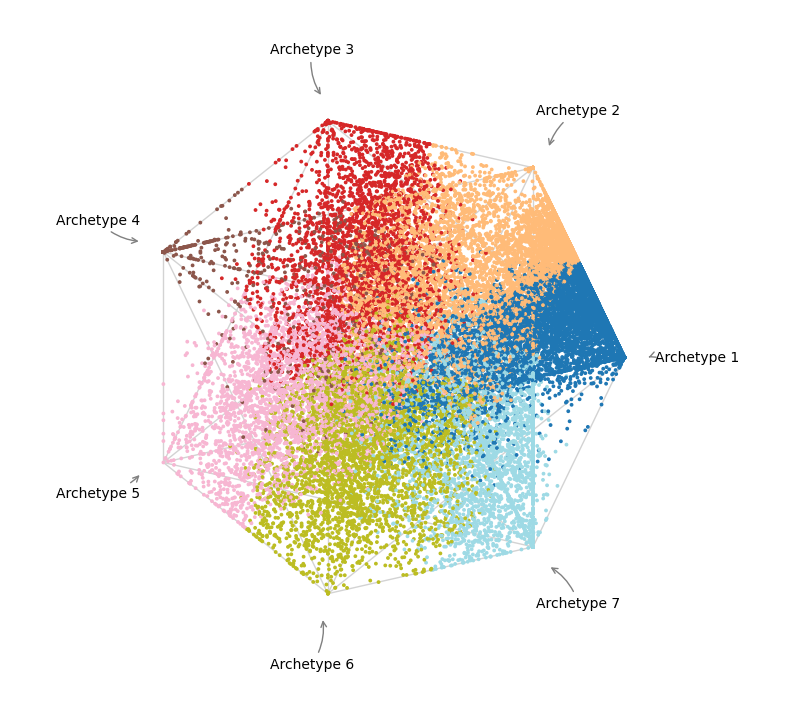

In [47]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels
otu_aa_swapped = otu_aa.copy()

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa.to_numpy(), alpha=1, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa.columns)


### Reordering (optional)
Sometimes the graph is quite messy, with prominent lines going through the middle. <br>
You may find it helpful to reorder the archetypes. This can be done by changing the array below in order
Caution: This depends on how many archetypes there are. You may have to change the ordering for each new result loaded. 

In [48]:
otu_aa_swapped = otu_aa[[ "Archetype 1","Archetype 2", "Archetype 7", "Archetype 3","Archetype 6", "Archetype 4", "Archetype 5"]]
# otu_aa_swapped = otu_aa
# otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 3", "Archetype 5", "Archetype 6", "Archetype 2" , "Archetype 4"]]

### Plotting by Filter with Color
Below is the usage of the plot_simplex() utility for plotting by location. Here, `filter_cols` contains the columns of the sample dataset to filter by. <br>
`legend_type` parameter sets whether the values are "discrete" or "continuous"

Project columns: []
Sample columns: ['region']
Tag columns: []


<Axes: >

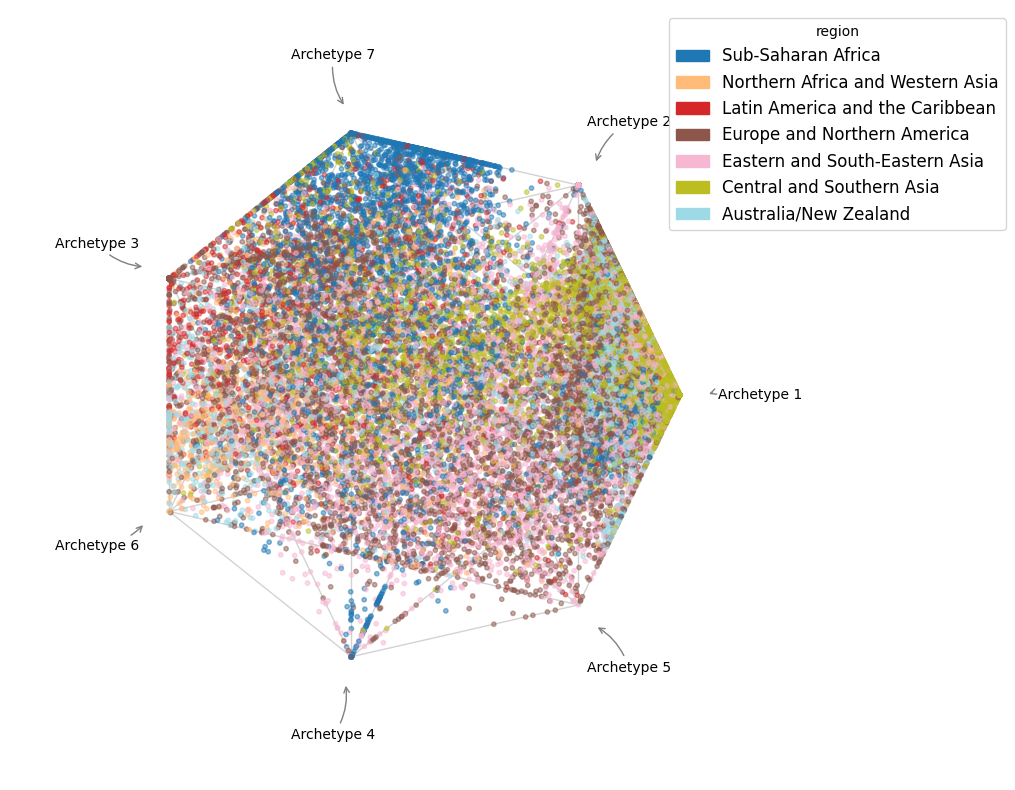

In [54]:
filter_cols = ["region"]
metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols, verbose=True)
simplex_plotter.plot_simplex(
    otu_aa=otu_aa_swapped, 
    metadata=metadata, 
    filter_cols=filter_cols, 
    cmap_name="tab20", 
    legend_type="discrete", 
    remove_nan=True,
    alpha = 0.5,
    s=10,
    remove_values={"region": "unknown"},
    figsize=(12, 10)
)

Similarly, for age. This time, the `legend_type` is "continuous"

In [ ]:
filter_cols = ["age_months"]
metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols, verbose=True)
simplex_plotter.plot_simplex(
    otu_aa=otu_aa_swapped,
    metadata=metadata,
    filter_cols=filter_cols,
    cmap_name="viridis",
    legend_type="continuous",
    remove_nan=True,
    alpha = 0.5,
    s=10,
    remove_values={"age_months": "unknown"},
    figsize=(12, 10)
)


### Group Plotting

c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\data\loaders.py:29: DtypeWarning: Columns (3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(filepath, index_col=index_col, **kwargs)
  0%|          | 0/6 [00:00<?, ?it/s]c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\simplex.py:156: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead.

(<Figure size 1600x1920 with 12 Axes>,
 array([[<Axes: title={'center': 'K = 3'}>,
         <Axes: title={'center': 'K = 6'}>],
        [<Axes: title={'center': 'K = 7'}>,
         <Axes: title={'center': 'K = 8'}>],
        [<Axes: title={'center': 'K = 10'}>,
         <Axes: title={'center': 'K = 12'}>]], dtype=object))

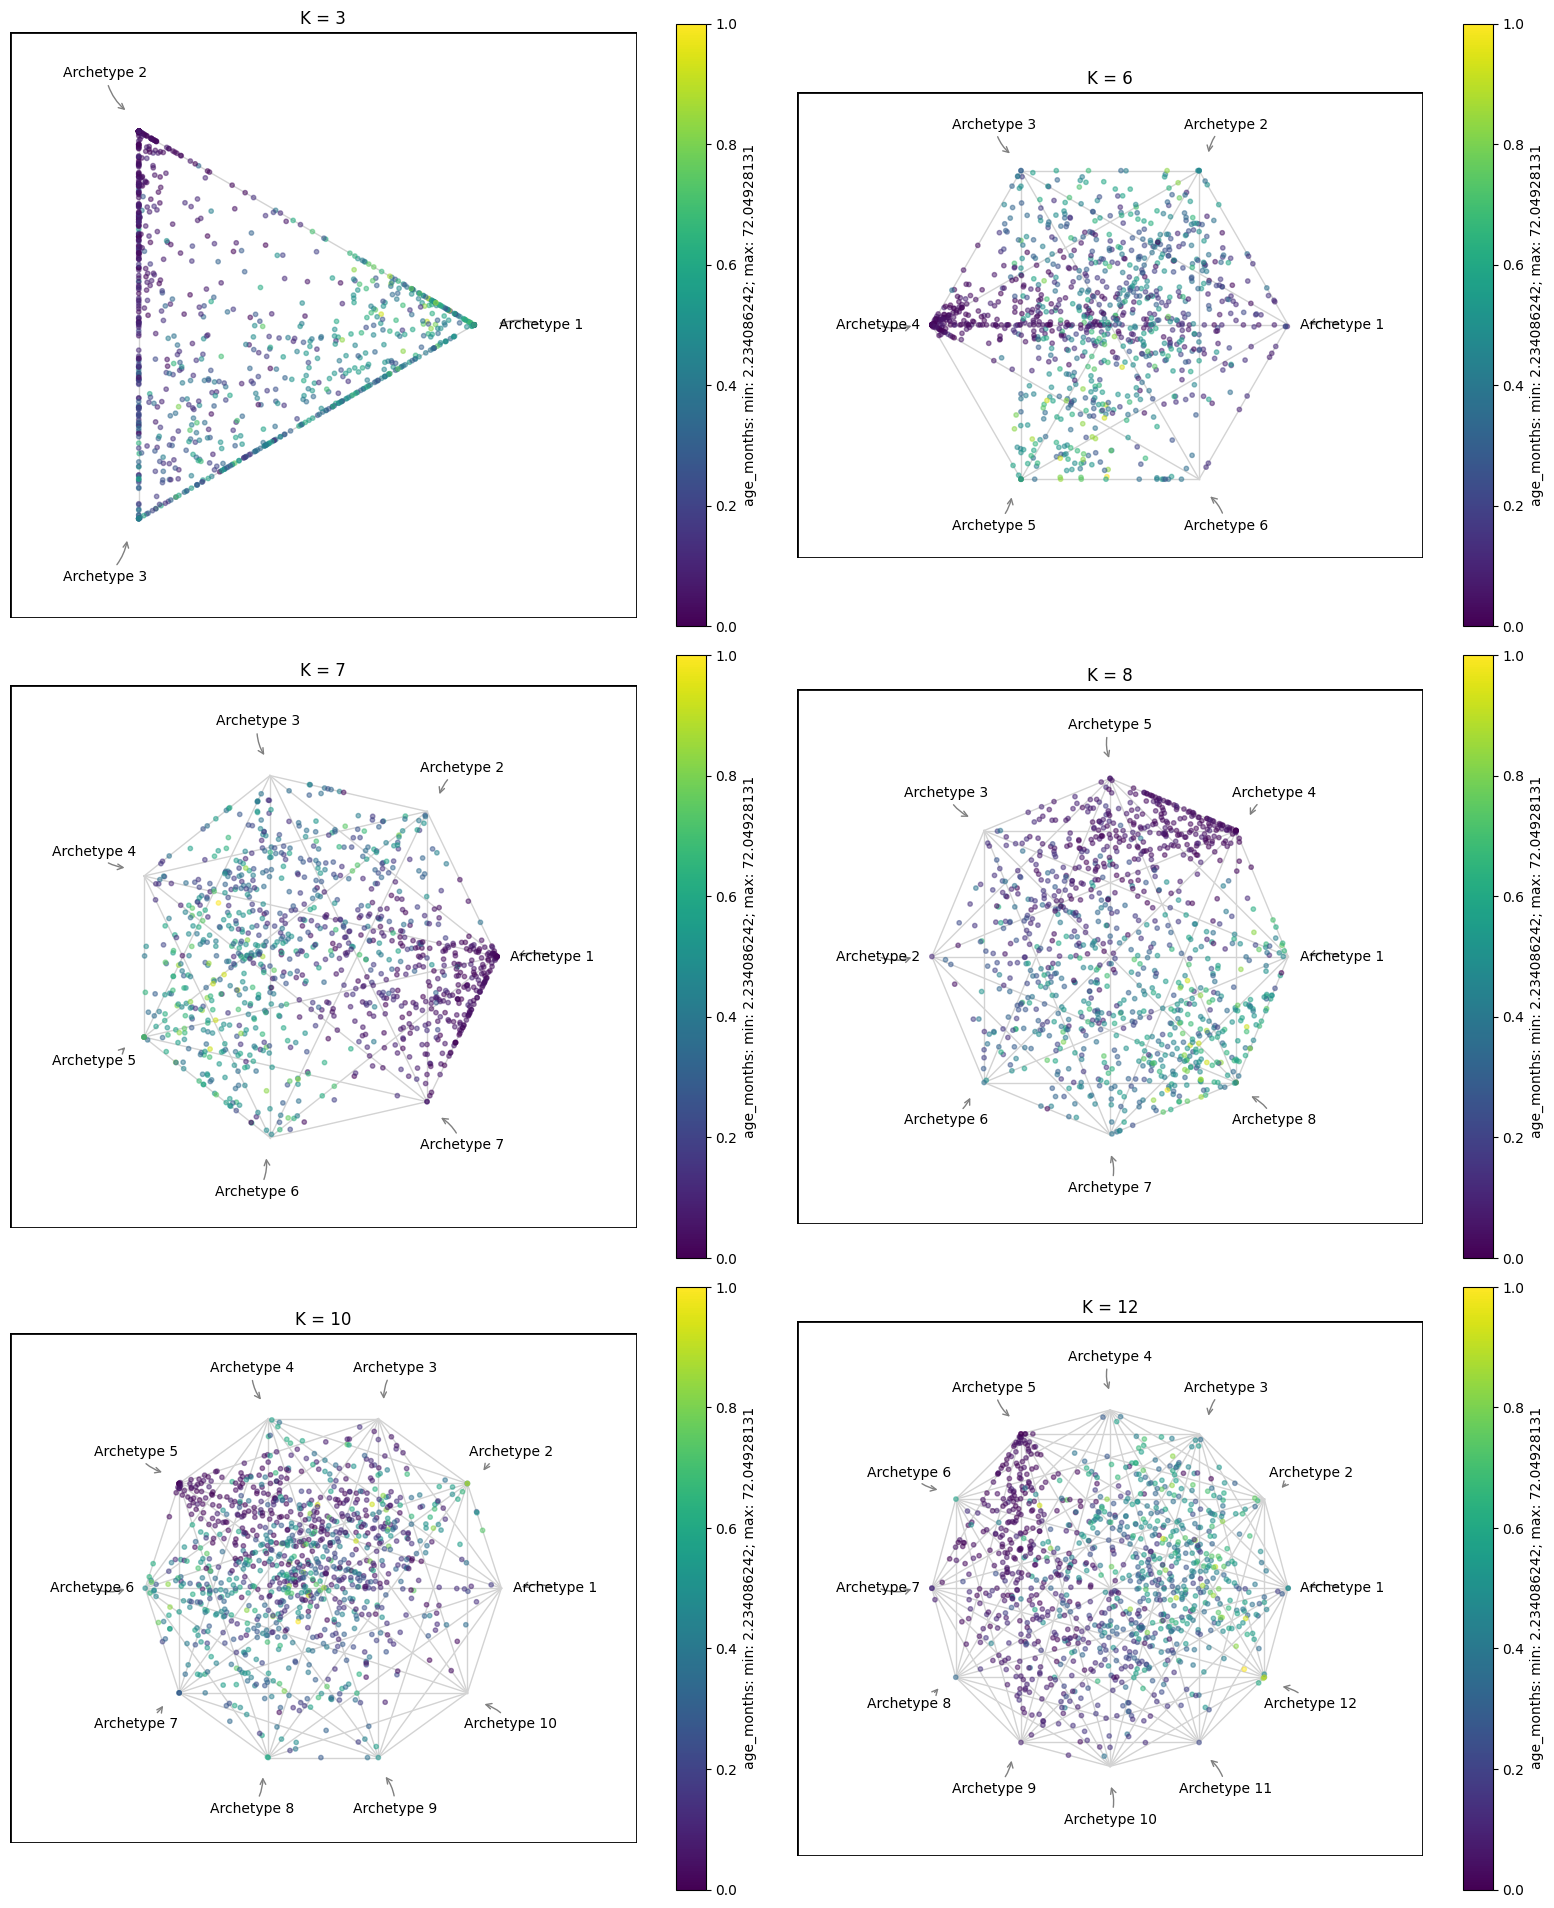

In [66]:
hadza_loader = HadzaDataLoader()
otu, meta, tax = hadza_loader.load_all(meta_file=r"datasets\tsv\hadza_meta_formatted.tsv")

dir = r"results\Hadza\norm_qc_age1k"
filter_cols = ["age_months"]
legend_type = "continuous" # "discrete" 

remove_values = {} #{"sample_type": "unknown"}

numKs =  [3,6,7,8,10,12] #[3,6,7,8,9,11] # 
swapped_cols = {
    # Region7k 
    # 8: ["Archetype 1", "Archetype 4", "Archetype 8", "Archetype 7", "Archetype 6", "Archetype 2", "Archetype 5", "Archetype 3"],
    # Region30k
    # 7: [ "Archetype 1","Archetype 2", "Archetype 7", "Archetype 3","Archetype 6", "Archetype 4", "Archetype 5"]
    # Region3k_AdultsOnly
    # 10: ["Archetype 1", "Archetype 2", "Archetype 3", "Archetype 9", "Archetype 4", "Archetype 8", "Archetype 5", "Archetype 6", "Archetype 7",  "Archetype 10"],
    # Hadza Region10k
    # 7: ["Archetype 1", "Archetype 3", "Archetype 6", "Archetype 2",  "Archetype 4", "Archetype 7", "Archetype 5"],
    # Hadza Age1k
    8: ["Archetype 1", "Archetype 4", "Archetype 5","Archetype 3", "Archetype 2",  "Archetype 6", "Archetype 7", "Archetype 8"],
}

simplex_plotter.plot_group_simplex(
    directory=dir, 
    k_values=numKs,
    filter_cols=filter_cols, 
    swapped_cols=swapped_cols, 
    legend_type=legend_type, 
    projects=projects, meta=meta, tags=tags,
    remove_values=remove_values, 
    cmap_name="viridis", 
    alpha = 0.5,
    s=10,
)

## Display Archetype Composition

In [100]:
otu_file = r"datasets\compendium\normalized\compendium_Norm_QC-region30k.csv"
loader = CompendiumDataLoader()
otu = loader.load_otu_table(filename=otu_file)

fName = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region30k\otu_AA_K7_1.0_None_jensenshannon.json"
loader = ArchetypalResultLoader()
otu_aa, aa_labels, aa_archetypes, info = loader.load_parsed_result(filepath)


In [102]:
composition_analyzer = CompositionAnalyzer()
NUM_TAXA = 5
top_taxa_archs = composition_analyzer.analyze_top_taxa(
    archetypes=aa_archetypes,
    feature_names=otu.columns,
    num_taxa=NUM_TAXA,
)


c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\composition.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_ylim(0, max_val)
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\composition.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_ylim(0, max_val)
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\composition.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_ylim(0, max_val)
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analys

(<Figure size 1500x800 with 8 Axes>,
 array([<Axes: title={'center': 'Archetype 1'}>,
        <Axes: title={'center': 'Archetype 2'}>,
        <Axes: title={'center': 'Archetype 3'}>,
        <Axes: title={'center': 'Archetype 4'}>,
        <Axes: title={'center': 'Archetype 5'}>,
        <Axes: title={'center': 'Archetype 6'}>,
        <Axes: title={'center': 'Archetype 7'}>, <Axes: >], dtype=object))

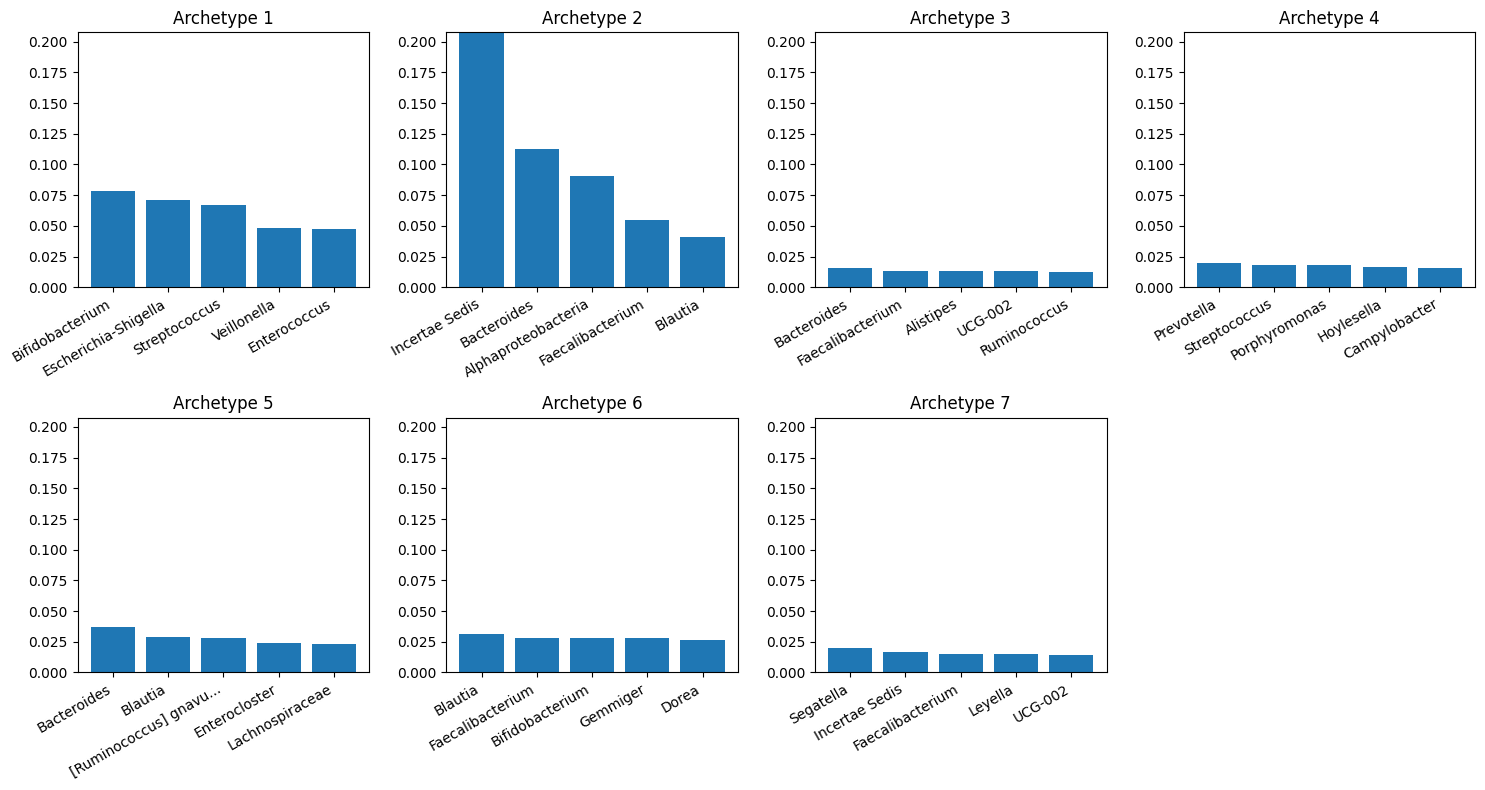

In [114]:
composition_analyzer.plot_separate_bar_charts(top_taxa_archetypes= top_taxa_archs)

In [110]:
all_top_taxa = set()
for arch_data in top_taxa_archs:
    for val, taxa in arch_data[:-1]:  # Exclude "Others"
        all_top_taxa.add(taxa)
archetype_names = [f"Archetype {i+1}" for i in range(7)]
all_top_taxa = sorted(list(all_top_taxa))

perc_matrix = composition_analyzer._create_taxa_percentage_matrix(top_taxa_archs, all_top_taxa, archetype_names)

(<Figure size 1200x800 with 1 Axes>,
 <Axes: title={'center': 'Stacked Bar Chart: Top Taxa Contribution by Archetype'}, xlabel='Archetypes', ylabel='Percentage Contribution (%)'>)

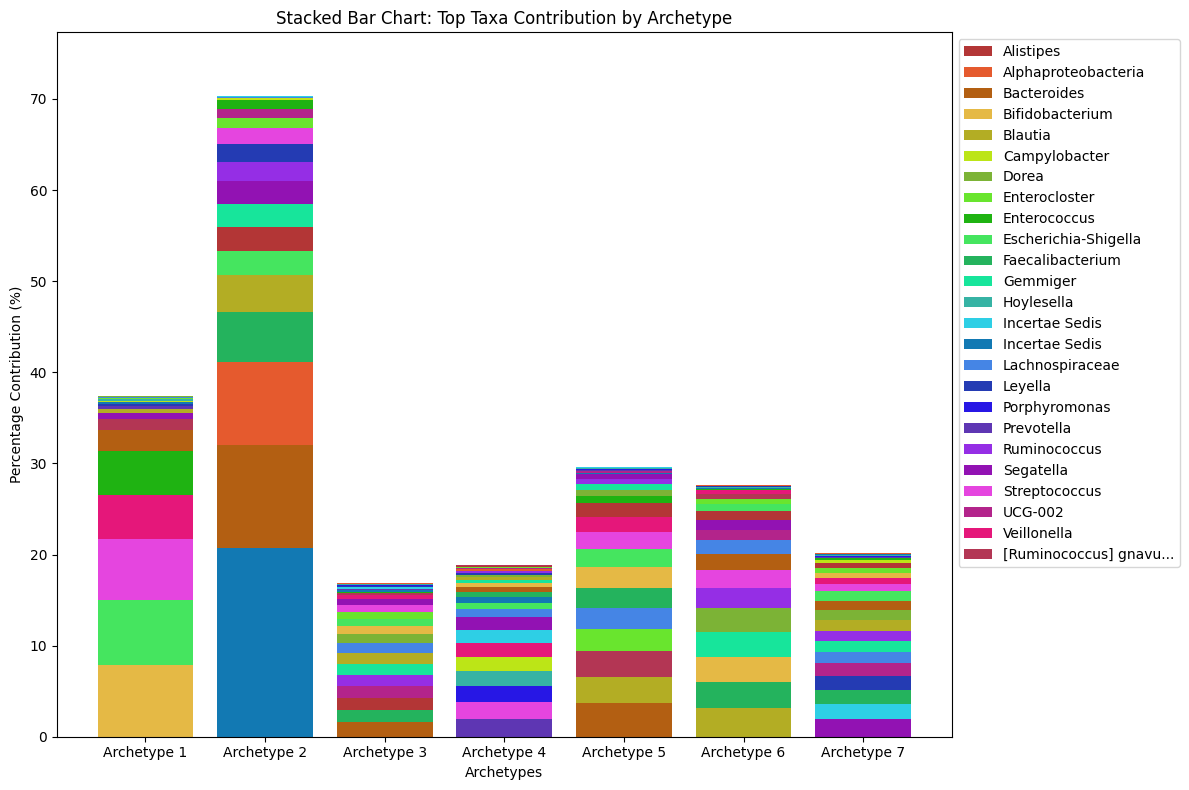

In [126]:
composition_analyzer.plot_stacked_bar_chart(aa_archetypes=aa_archetypes, feature_names=otu.columns, top_taxa_archetypes=top_taxa_archs)

## PCoA Comparison

In [137]:
data_loader = CompendiumDataLoader()
otu_file = r"datasets\compendium\normalized\compendium_Norm_QC-sample_type400.csv"
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets/compendium/sample_metadata.tsv"
otu, projects, tags, meta = data_loader.load_all(otu_file=otu_file, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)


In [145]:
filter_cols = ["sample_type"]
legend_type = "discrete"  # "continuous" or "discrete"
metadata = extract_metadata_compendium(otu.index, tags, meta, projects, filter_cols, verbose=False)

pcoa_visualizer = PCoAVisualizer()
pcoa_coords, pcoa_results = pcoa_visualizer.create_pcoa_from_otu(
    otu_data=otu,
    distance_metric="jensenshannon",
    n_dimensions=5,
    apply_log_transform=True,
    clean_data=True,
    verbose=False
)


c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\pcoa.py:106: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  x_explained = pcoa_results.proportion_explained[int(x_pc[-1])-1]
c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\visualization\pcoa.py:107: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_explained = pcoa_results.proportion_explained[int(y_pc[-1])-1]


(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'PC1 vs PC2'}, xlabel='PC1 (16.41% variance explained)', ylabel='PC2 (6.32% variance explained)'>,
        <Axes: title={'center': 'PC2 vs PC3'}, xlabel='PC2 (6.32% variance explained)', ylabel='PC3 (4.57% variance explained)'>,
        <Axes: title={'center': 'PC1 vs PC3'}, xlabel='PC1 (16.41% variance explained)', ylabel='PC3 (4.57% variance explained)'>],
       dtype=object))

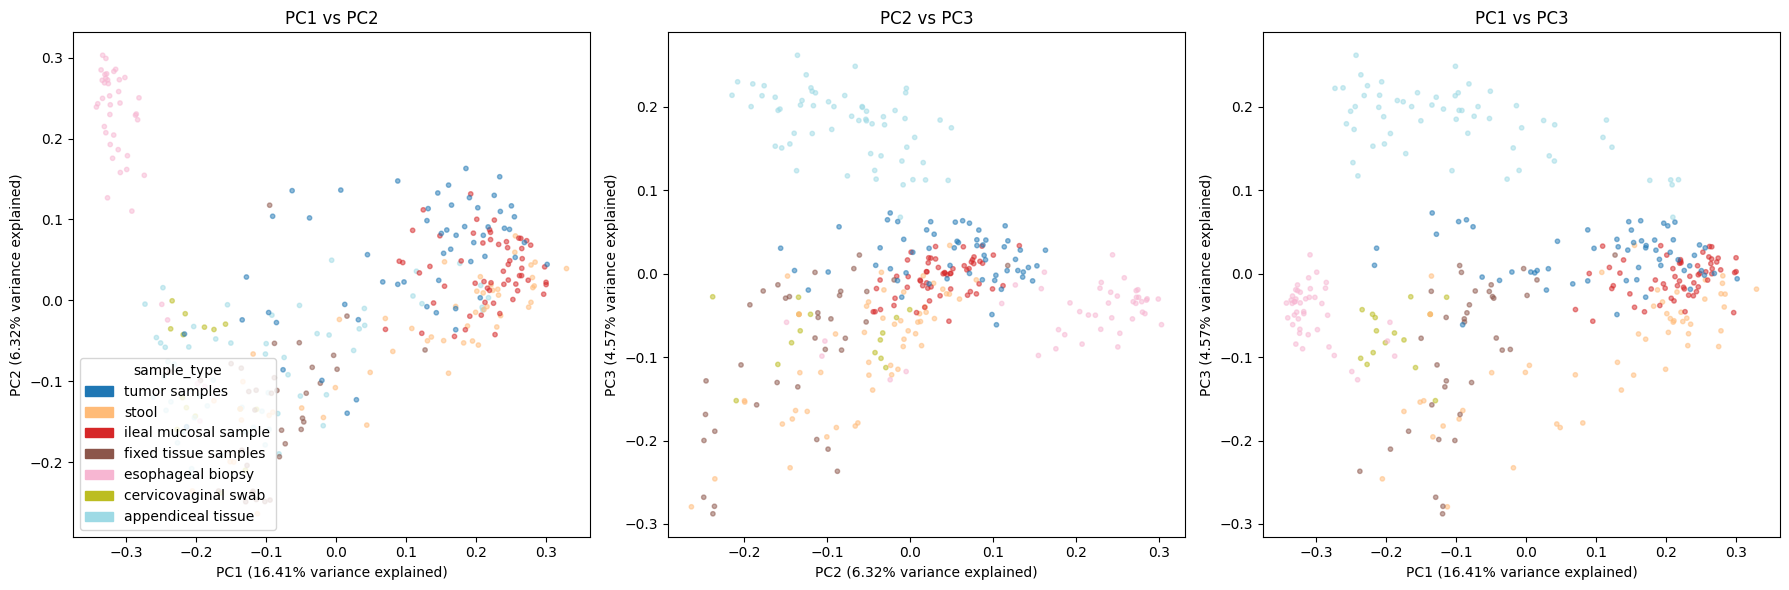

In [146]:
pcoa_visualizer.plot_pcoa(
    pcoa_coordinates=pcoa_coords, 
    pcoa_results=pcoa_results,
    metadata=metadata, 
    filter_col=filter_cols[0],
    legend_type=legend_type,
    pc_combinations=[('PC1', 'PC2'), ('PC2', 'PC3'), ('PC1', 'PC3')]
)

## Num Archs Analysis

In [150]:
data_loader = CompendiumDataLoader()
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets/compendium/sample_metadata.tsv"
_, projects, tags, meta = data_loader.load_all(otu_file=otu_file, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)


In [172]:
loader = ArchetypalResultLoader()
resultsDir = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-sample_type400"
nIdx_archs = [3,4,5,6,7,8,9,10,11,12]
k_results = loader.load_multiple_results(k_values=nIdx_archs, directory=resultsDir)

Evaluating K: 100%|██████████| 10/10 [00:00<00:00, 110.83it/s]


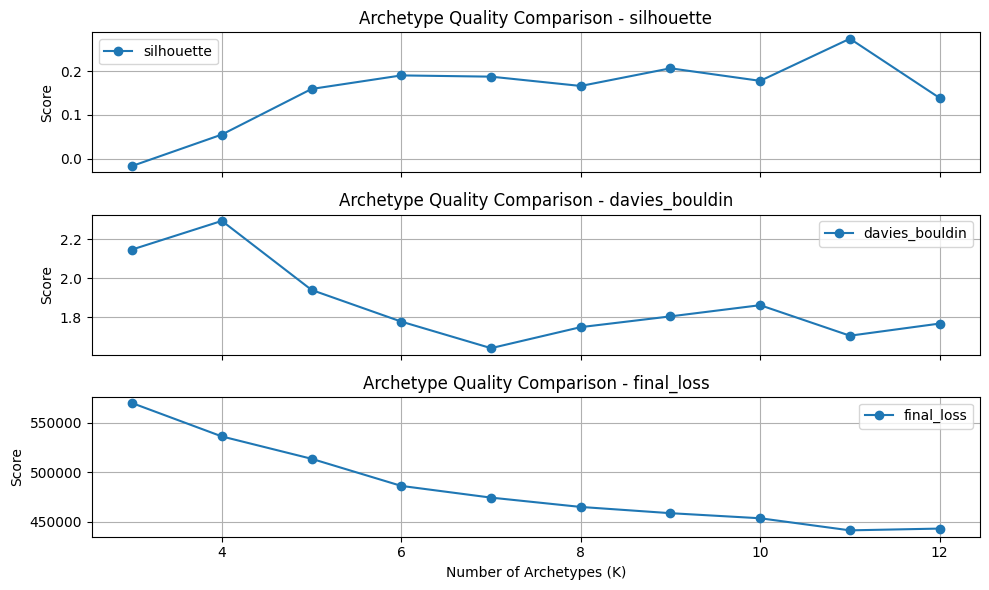

In [180]:
filter_cols = ["sample_type"]
discretize = False
metadata = extract_metadata_compendium(k_results[nIdx_archs[0]]["index"], tags, meta, projects, filter_cols, verbose=False)

analysis_metrics = AnalysisMetrics()
analysis_results = analysis_metrics.compare_archetype_quality(
    results_dict=k_results,
    metadata=metadata,
    metadata_column=filter_cols[0], 
    discretize=False, 
    buckets=None, 
    metrics=["silhouette", "davies_bouldin", 'final_loss']
)
analysis_metrics.plot_comparison(comparison_df=analysis_results, figsize=(10, 6))

## Stacked Bar 

In [14]:
compendium_loader = CompendiumDataLoader() # HadzaDataLoader()
projects_file = r"datasets/compendium/projects.csv"
tags_file = r"datasets/compendium/tags.tsv"
meta_file = r"datasets\tsv\hadza_meta_formatted.tsv"
_, projects, tags, meta = compendium_loader.load_all(otu_file=None, projects_file=projects_file, tags_file=tags_file, meta_file=meta_file)

filepath = r"results\Hadza\norm_qc_age1k\otu_AA_K8_1.0_None_jensenshannon.json"
loader = ArchetypalResultLoader()
otu_aa, aa_labels, aa_archetypes, info = loader.load_parsed_result(filepath)


c:\Users\rayve\Documents\NYU\Research Work\Genetic Heritage Group\Archetypal Analysis\archetypal_analysis\data\loaders.py:31: DtypeWarning: Columns (3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_table(filepath, index_col=index_col, **kwargs)


<Axes: ylabel='Similarity degree'>

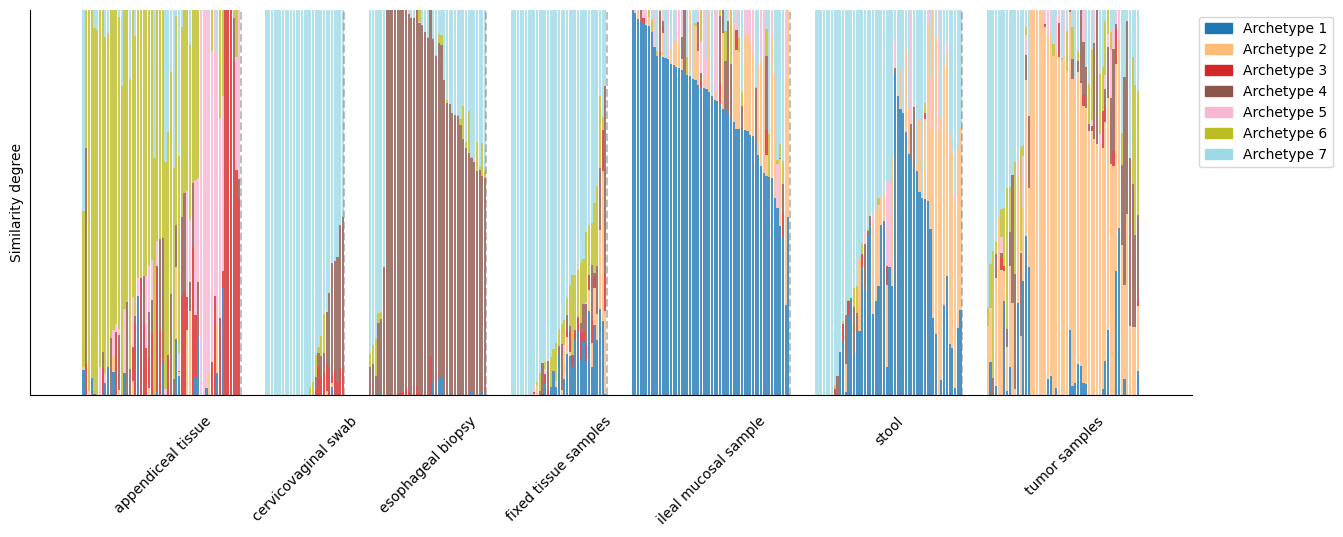

In [6]:
stacked_bar_plotter = StackedBarPlotter()
filter_cols = ["sample_type"]
metadata = extract_metadata_compendium(otu_aa.index, tags, meta, projects, extract_cols=filter_cols, verbose=False)
stacked_bar_plotter.plot_metadata_stacked_bars(
    similarity_degree=otu_aa, 
    metadata=metadata,
    perms=info.get('perms', None),
    metadata_column=filter_cols[0],
    discretize=False,
    buckets=None,

)

Project columns: []
Sample columns: ['age_months']
Tag columns: []


<Axes: xlabel='Observations', ylabel='Similarity degree'>

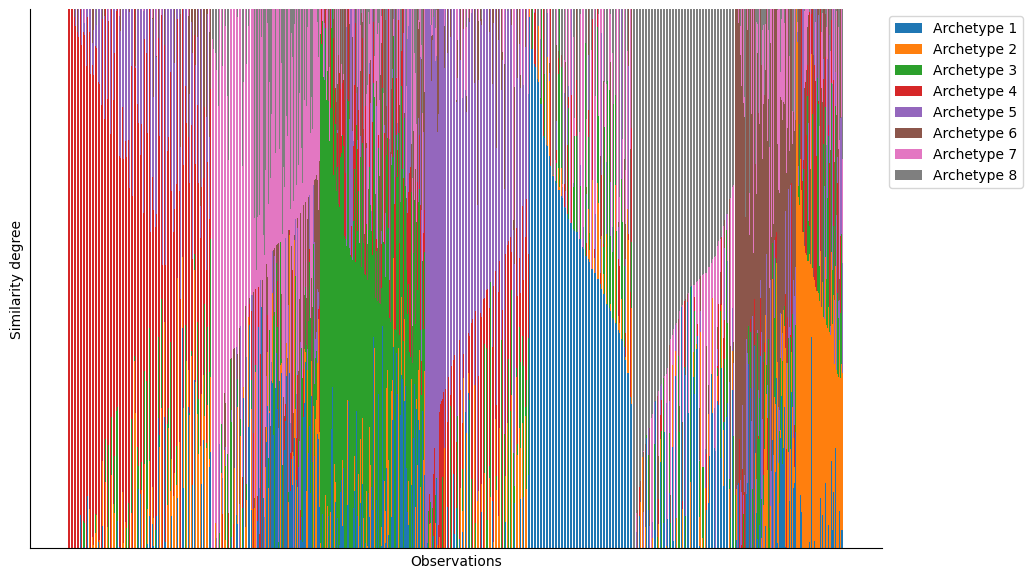

In [18]:
stacked_bar_plotter = StackedBarPlotter()
buckets = [(0,6), (6,12), (12,24), (24,36), (36,48), (48,60), (60, np.inf)]
filter_cols = ["age_months"]
metadata = extract_metadata_compendium(otu_aa.index, None, meta, None, extract_cols=filter_cols, verbose=True)
stacked_bar_plotter.plot_metadata_stacked_bars(
    similarity_degree=otu_aa, 
    metadata=metadata,
    perms=info.get('perms', None),
    metadata_column=None,
    figsize=(11,7),
)